In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


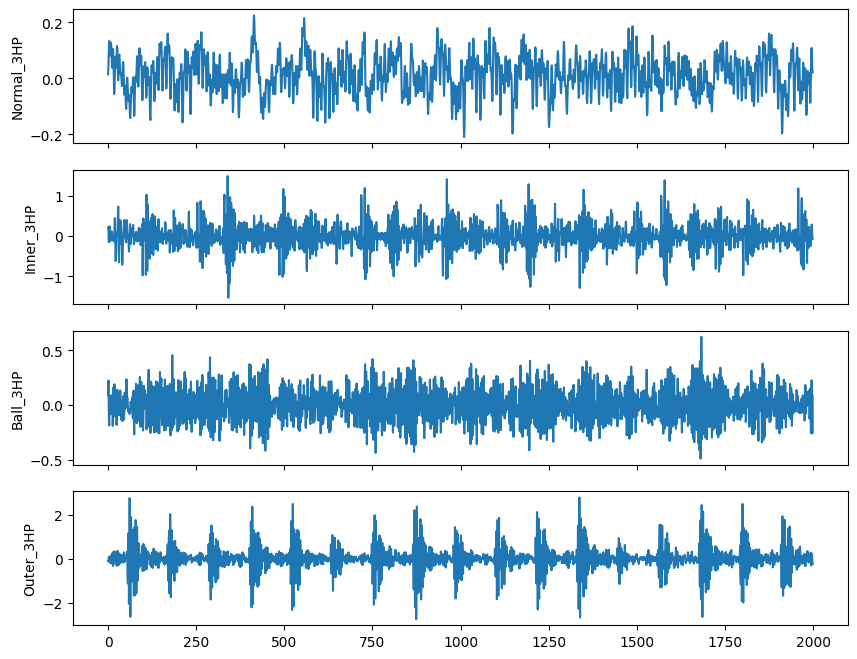

In [2]:
import numpy as np, scipy.io as sio, matplotlib.pyplot as plt
DATA = '/content/drive/MyDrive/cwru/'

def load(num):
    m = sio.loadmat(f'{DATA}{num}.mat')
    key = [k for k in m if k.endswith('DE_time')][0]   # 驅動端加速度訊號
    return m[key].squeeze()

files = {'Normal_3HP':100, 'Inner_3HP':108, 'Ball_3HP':121, 'Outer_3HP':133}
fig, axs = plt.subplots(len(files), 1, figsize=(10, 8), sharex=True)
for ax, (name, n) in zip(axs, files.items()):
    ax.plot(load(n)[:2000]); ax.set_ylabel(name)
plt.show()

In [4]:
def windows(x, size=1024, step=512):
    n = (len(x) - size) // step + 1
    return np.stack([x[i*step : i*step+size] for i in range(n)])

In [5]:
Xtrain      = np.concatenate([windows(load(n)) for n in (97, 98, 99)])
Xtest_norm  = windows(load(100))
Xtest_fault = np.concatenate([windows(load(n)) for n in (108, 121, 133)])

Xtest  = np.concatenate([Xtest_norm, Xtest_fault])
y_true = np.r_[np.zeros(len(Xtest_norm)), np.ones(len(Xtest_fault))]  # 0=正常, 1=異常
print(Xtrain.shape, Xtest_norm.shape, Xtest_fault.shape)

(2363, 1024) (947, 1024) (713, 1024)


In [6]:
from sklearn.metrics import roc_auc_score, f1_score

def rms(w): return np.sqrt((w**2).mean(axis=1))

score = rms(Xtest)
thr   = rms(Xtrain).mean() + 3 * rms(Xtrain).std()
pred  = score > thr

print('RMS AUROC:', roc_auc_score(y_true, score))
print('RMS F1   :', f1_score(y_true, pred))

RMS AUROC: 1.0
RMS F1   : 1.0


In [7]:
rng = np.random.default_rng(0)

for sigma in [0, 0.1, 0.2, 0.4, 0.8, 1.6]:
    tr = Xtrain + rng.normal(0, sigma, Xtrain.shape)
    te = Xtest  + rng.normal(0, sigma, Xtest.shape)
    thr  = rms(tr).mean() + 3 * rms(tr).std()
    auc  = roc_auc_score(y_true, rms(te))
    f1   = f1_score(y_true, rms(te) > thr)
    print(f'sigma={sigma:<4}  AUROC={auc:.3f}  F1={f1:.3f}')

sigma=0     AUROC=1.000  F1=1.000
sigma=0.1   AUROC=1.000  F1=1.000
sigma=0.2   AUROC=1.000  F1=0.999
sigma=0.4   AUROC=0.986  F1=0.873
sigma=0.8   AUROC=0.897  F1=0.683
sigma=1.6   AUROC=0.743  F1=0.275


In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_ae():
    return models.Sequential([
        layers.Input((1024, 1)),
        # 編碼：1024 點壓縮成 32x8 = 256 個數值
        layers.Conv1D(16, 9, strides=4, padding='same', activation='relu'),
        layers.Conv1D(16, 9, strides=4, padding='same', activation='relu'),
        layers.Conv1D(8,  9, strides=2, padding='same', activation='relu'),
        # 解碼：還原回 1024 點
        layers.Conv1DTranspose(16, 9, strides=2, padding='same', activation='relu'),
        layers.Conv1DTranspose(16, 9, strides=4, padding='same', activation='relu'),
        layers.Conv1DTranspose(16, 9, strides=4, padding='same', activation='relu'),
        layers.Conv1D(1, 9, padding='same'),
    ])

def ae_error(model, x):
    return np.mean((model.predict(x, verbose=0) - x) ** 2, axis=(1, 2))

def run(sigma, epochs=30):
    tf.keras.utils.set_random_seed(0)
    rng = np.random.default_rng(0)
    tr = Xtrain + rng.normal(0, sigma, Xtrain.shape)
    te = Xtest  + rng.normal(0, sigma, Xtest.shape)

    # RMS 基準線（和之前完全相同的規則）
    thr_r = rms(tr).mean() + 3 * rms(tr).std()
    auc_r = roc_auc_score(y_true, rms(te))
    f1_r  = f1_score(y_true, rms(te) > thr_r)

    # 用「訓練資料整體」的平均與標準差標準化（不是每個視窗各自標準化）
    mu, sd = tr.mean(), tr.std()
    tr_n = ((tr - mu) / sd)[..., None].astype('float32')
    te_n = ((te - mu) / sd)[..., None].astype('float32')

    ae = build_ae()
    ae.compile(optimizer='adam', loss='mse')
    ae.fit(tr_n, tr_n, epochs=epochs, batch_size=64, shuffle=True, verbose=0)

    e_tr, e_te = ae_error(ae, tr_n), ae_error(ae, te_n)
    thr_a = e_tr.mean() + 3 * e_tr.std()      # 同樣的「平均+3倍標準差」規則
    auc_a = roc_auc_score(y_true, e_te)
    f1_a  = f1_score(y_true, e_te > thr_a)

    print(f'sigma={sigma:<4} | RMS  AUROC={auc_r:.3f} F1={f1_r:.3f} '
          f'| AE  AUROC={auc_a:.3f} F1={f1_a:.3f}')
    return ae, mu, sd

models_by_sigma = {}
for s in [0.4, 0.8, 1.6]:
    models_by_sigma[s] = run(s)

sigma=0.4  | RMS  AUROC=0.987 F1=0.881 | AE  AUROC=0.993 F1=0.933
sigma=0.8  | RMS  AUROC=0.895 F1=0.680 | AE  AUROC=0.896 F1=0.693
sigma=1.6  | RMS  AUROC=0.749 F1=0.260 | AE  AUROC=0.737 F1=0.226


In [9]:
import time

sigma = 0.4
ae, mu, sd = models_by_sigma[sigma]

# 重建和 run() 裡完全相同的資料（亂數種子一樣）
rng = np.random.default_rng(0)
tr = Xtrain + rng.normal(0, sigma, Xtrain.shape)
te = Xtest  + rng.normal(0, sigma, Xtest.shape)
tr_n = ((tr - mu) / sd)[..., None].astype('float32')
te_n = ((te - mu) / sd)[..., None].astype('float32')

# 量化需要一些「代表性資料」來校準數值範圍
idx = np.random.default_rng(1).choice(len(tr_n), 200, replace=False)
def rep_data():
    for i in idx:
        yield [tr_n[i:i+1]]

# 轉成 TFLite：float32 版與 int8 量化版
tflite_f32 = tf.lite.TFLiteConverter.from_keras_model(ae).convert()

conv = tf.lite.TFLiteConverter.from_keras_model(ae)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = rep_data
tflite_int8 = conv.convert()

print('參數量:', ae.count_params())
print('float32 模型大小: %.1f KB' % (len(tflite_f32) / 1024))
print('int8    模型大小: %.1f KB' % (len(tflite_int8) / 1024))

# 用 TFLite 直譯器逐筆推論，算重建誤差
def tflite_errors(model_bytes, x):
    it = tf.lite.Interpreter(model_content=model_bytes)
    it.allocate_tensors()
    i_in  = it.get_input_details()[0]['index']
    i_out = it.get_output_details()[0]['index']
    errs = []
    for k in range(len(x)):
        it.set_tensor(i_in, x[k:k+1])
        it.invoke()
        errs.append(np.mean((it.get_tensor(i_out) - x[k:k+1]) ** 2))
    return np.array(errs)

def evaluate(name, e_tr, e_te):
    thr = e_tr.mean() + 3 * e_tr.std()
    print(f'{name:8s} AUROC={roc_auc_score(y_true, e_te):.3f}  '
          f'F1={f1_score(y_true, e_te > thr):.3f}')

evaluate('Keras',   ae_error(ae, tr_n), ae_error(ae, te_n))
evaluate('TFLite32', tflite_errors(tflite_f32, tr_n), tflite_errors(tflite_f32, te_n))
evaluate('TFLite8',  tflite_errors(tflite_int8, tr_n), tflite_errors(tflite_int8, te_n))

# 單一視窗推論時間（Colab 的 CPU，不是樹莓派）
def latency_ms(model_bytes, n=200):
    it = tf.lite.Interpreter(model_content=model_bytes)
    it.allocate_tensors()
    i_in = it.get_input_details()[0]['index']
    for _ in range(10):                       # 先暖機
        it.set_tensor(i_in, te_n[:1]); it.invoke()
    t = time.perf_counter()
    for k in range(n):
        it.set_tensor(i_in, te_n[k:k+1]); it.invoke()
    return (time.perf_counter() - t) / n * 1000

print('float32 延遲: %.2f ms / 視窗' % latency_ms(tflite_f32))
print('int8    延遲: %.2f ms / 視窗' % latency_ms(tflite_int8))

open('ae_float32.tflite', 'wb').write(tflite_f32)
open('ae_int8.tflite', 'wb').write(tflite_int8)

Saved artifact at '/tmp/tmphu1gtxsr'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 1024, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1024, 1), dtype=tf.float32, name=None)
Captures:
  139780033359184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139780033360336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139780033359760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139780033360912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139780033360720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139780033359952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139780033354768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139780033361872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139780033361296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139780033362064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139780033360

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


參數量: 9593
float32 模型大小: 49.6 KB
int8    模型大小: 25.3 KB
Keras    AUROC=0.993  F1=0.933


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite32 AUROC=0.993  F1=0.933


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite8  AUROC=0.993  F1=0.933
float32 延遲: 0.21 ms / 視窗
int8    延遲: 0.31 ms / 視窗


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


25920

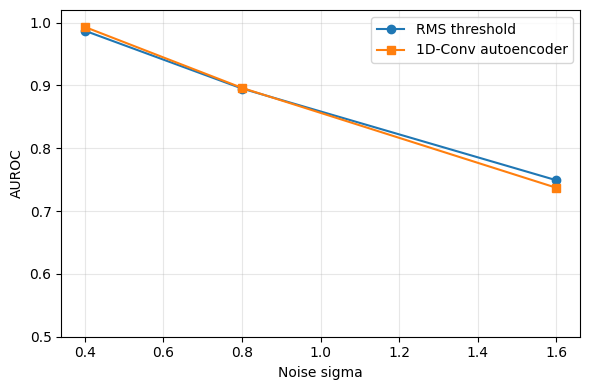

In [10]:
sig   = [0.4, 0.8, 1.6]
rmsA  = [0.987, 0.895, 0.749]
aeA   = [0.993, 0.896, 0.737]

plt.figure(figsize=(6,4))
plt.plot(sig, rmsA, 'o-', label='RMS threshold')
plt.plot(sig, aeA,  's-', label='1D-Conv autoencoder')
plt.xlabel('Noise sigma'); plt.ylabel('AUROC'); plt.ylim(0.5, 1.02)
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig('auroc_vs_noise.png', dpi=200); plt.show()